# Project: Young Adult Migration Patterns with Neural Networks
### Soren Patel

**AI Usage:** Generative AI was used to assist with selecting relevant workflow components from the previous lab, generating visualization plots, and interpreting the ablation results. All code, data processing, and analytical conclusions were verified independently. This was also written by AI.

## Data Loading/Setup/Configuration

Import necessary libraries and give a value to seed random for reproducible results. Also includes flags EXCLUDE_SAME_CZ which when true, will indicate dropping rows for people who did not move. LOG_TARGET flag when true predicts a log(1+n) instead of n, so the range is compressed and right-skewed migration counts do not pull the regression line as heavily. Note we use 1+n inside the log since log(0) is undefined.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import torch, torch.nn as nn, torch.optim as optim


RANDOM_STATE = 2028
DATA_PATH = "od_pooled.csv"
EXCLUDE_SAME_CZ = True
LOG_TARGET = True

Load the data from od_pooled.csv (main dataset). Each row is one origin and destination pair, with the amount of people who made that move. Print first 5 rows for visualization.

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df.columns.tolist())
df.head()

(549081, 12)
['o_cz', 'o_cz_name', 'o_state_name', 'd_cz', 'd_cz_name', 'd_state_name', 'n', 'n_tot_o', 'n_tot_d', 'pool', 'pr_d_o', 'pr_o_d']


,o_cz,o_cz_name,o_state_name,d_cz,d_cz_name,d_state_name,n,n_tot_o,n_tot_d,pool,pr_d_o,pr_o_d
0,6502,Cleveland,Tennessee,100,Johnson City,Tennessee,127.0,22148,56915,pooled,0.005734,0.002231
1,34108,Kodiak,Alaska,100,Johnson City,Tennessee,0.0,1702,56915,pooled,0.000000,0.000000
2,10302,Dothan,Alabama,100,Johnson City,Tennessee,16.0,26182,56915,pooled,0.000611,0.000281
3,5201,New Albany,Mississippi,100,Johnson City,Tennessee,1.0,6530,56915,pooled,0.000153,0.000018
4,29201,Hiawatha,Kansas,100,Johnson City,Tennessee,0.0,2794,56915,pooled,0.000000,0.000000


## Data Exploration  
Answering the following questions will better help us analyze the data since we can better characterize the dataset.  
  
How skewed is n?  
How many rows are 0/NaN?  
Does the file contain same-CZ rows?  
Does every origin-destination pair exist, or only ones with movers?

count    5.490810e+05
mean     5.722583e+01
std      3.263886e+03
min     -2.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      3.000000e+00
max      1.400000e+06
Name: n, dtype: float64

Rows with n < 0: 2388
Rows with n == 0: 284503
Rows with o_cz == d_cz: 741

Unique origins: 741, unique destinations: 741
Rows: 549081 vs all possible pairs: 549081


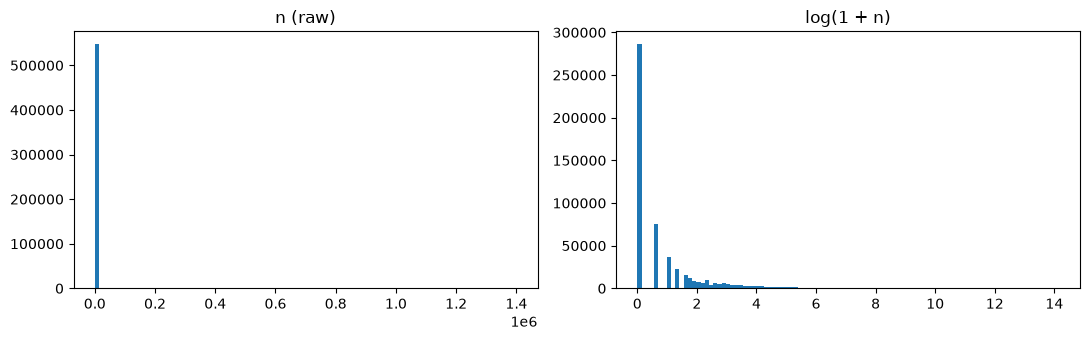

In [3]:
print(df["n"].describe())
print("\nRows with n < 0:", (df["n"] < 0).sum())
print("Rows with n == 0:", (df["n"] == 0).sum())
print("Rows with o_cz == d_cz:", (df["o_cz"] == df["d_cz"]).sum())

n_o, n_d = df["o_cz"].nunique(), df["d_cz"].nunique()
print(f"\nUnique origins: {n_o}, unique destinations: {n_d}")
print(f"Rows: {len(df)} vs all possible pairs: {n_o * n_d}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(df["n"].clip(lower=0), bins=100); ax[0].set_title("n (raw)")
ax[1].hist(np.log1p(df["n"].clip(lower=0)), bins=100); ax[1].set_title("log(1 + n)")
plt.tight_layout(); plt.show()

## Clean Data and Define Target for Model

Decisions made:  
1. The negative n values are set to 0 since they most likely come from privacy noise.
2. When EXCLUDE_SAME_CZ flag is true, the same-cz rows are dropped since not moving would skew the line.
3. Target is log(1+n) if LOG_TARGET flag is true, since the counts are heavily right-skewed.

In [4]:
data = df.copy()

if EXCLUDE_SAME_CZ:
    data = data[data["o_cz"] != data["d_cz"]]

n_neg = (data["n"] < 0).sum()
data["n_clean"] = data["n"].clip(lower=0)
print(f"Clipped {n_neg} negative counts to 0")

data["y"] = np.log1p(data["n_clean"]) if LOG_TARGET else data["n_clean"]
data = data.reset_index(drop=True)
print("Rows after cleaning:", len(data))

Clipped 2388 negative counts to 0
Rows after cleaning: 548340


## Split into Train/Test/Validation Data

Split into 80% train, 10% test, 10% validation sets.  
Note: the code may seem unintuitive, but it works by first removing 0.10 as the test set. Then taking 1/9th of that remaining 90% to be the validation set. Rest is the training set.

In [5]:
train_val, test = train_test_split(data, test_size=0.10, random_state=RANDOM_STATE)
train, val = train_test_split(train_val, test_size=1/9, random_state=RANDOM_STATE)

print(f"train: {len(train)}, val: {len(val)}, test: {len(test)}")

train: 438672, val: 54834, test: 54834


## Neural Network Model and Training Loop

Here is where the neural network is implemented. The output layer has no activation function. It will early stop if validation RMSE is less than the best by a certain margin, and only fits StandardScaler to the train data. Note: cpu is printed if no gpu is available for running. 

In [6]:
import torch, torch.nn as nn, torch.optim as optim
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

class NeuralNet(nn.Module):
    def __init__(self, D, H=128, depth=3, act=nn.ReLU):
        super().__init__()
        layers, d = [], D
        for _ in range(depth):
            layers += [nn.Linear(d, H), act()]
            d = H
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def train_net(Xt, yt, Xv, yv, H=128, depth=3, act=nn.ReLU, lr=1e-3,
              epochs=60, batch=2048, patience=8, seed=0, verbose=False):
    torch.manual_seed(seed)
    Xt = torch.tensor(Xt, dtype=torch.float32, device=device)
    yt = torch.tensor(np.asarray(yt), dtype=torch.float32, device=device).view(-1, 1)
    Xv = torch.tensor(Xv, dtype=torch.float32, device=device)
    yv = torch.tensor(np.asarray(yv), dtype=torch.float32, device=device).view(-1, 1)

    net = NeuralNet(Xt.shape[1], H, depth, act).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(net.parameters(), lr=lr)

    best, bad, best_state = float("inf"), 0, None
    for epoch in range(epochs):
        net.train()
        perm = torch.randperm(len(Xt), device=device)
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]
            outputs = net(Xt[idx])
            loss = criterion(outputs, yt[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        net.eval()
        with torch.no_grad():
            val_rmse = criterion(net(Xv), yv).sqrt().item()
        if verbose and (epoch + 1) % 10 == 0:
            print(f"Epoch [{epoch + 1}/{epochs}], val RMSE: {val_rmse:.4f}")
        if val_rmse < best - 1e-5: 
            best, bad = val_rmse, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    net.load_state_dict(best_state)
    return net, best

    def __init__(self, net): self.net = net
    def predict(self, X):
        self.net.eval()
        with torch.no_grad():
            return self.net(torch.tensor(X, dtype=torch.float32, device=device)).squeeze(1).cpu().numpy()

CONFIGS = [dict(H=64, depth=2), dict(H=128, depth=3),
           dict(H=256, depth=3, lr=5e-4), dict(H=128, depth=3, act=nn.Tanh)]

class TorchReg:
    def __init__(self, net): self.net = net
    def predict(self, X):
        self.net.eval()
        with torch.no_grad():
            return self.net(torch.tensor(X, dtype=torch.float32, device=device)).squeeze(1).cpu().numpy()

def fit_best_model(X_train, y_train, X_val, y_val, configs=None):
    configs = configs or CONFIGS
    scaler = StandardScaler().fit(X_train)
    Xt, Xv = scaler.transform(X_train), scaler.transform(X_val)
    best = None
    for cfg in configs:
        net, rmse = train_net(Xt, y_train, Xv, y_val, **cfg)
        if best is None or rmse < best["val_rmse"]:
            m = TorchReg(net)
            best = {"alpha": str(cfg), "model": m, "scaler": scaler, "val_rmse": rmse,
                    "val_r2": r2_score(y_val, m.predict(Xv)), "features": list(X_train.columns)}
    return best

device: cpu


## Inspect/Visualize Downloaded Files  
Print first few values of files to be used going forward.

In [7]:
import xlrd

xw = pd.read_csv("commuting-zones-2020.csv")
print("CZ file:", xw.columns.tolist()); display(xw.head(3))

pop_raw = pd.read_csv("co-est2020.csv", encoding="latin-1")
print("\nPopulation:", pop_raw.columns.tolist()[:12]); display(pop_raw.head(3).iloc[:, :8])

display(pd.read_excel("est20all.xls", header=None, nrows=6).iloc[:, :10])

xl = pd.ExcelFile("2020county_health_rankings.xlsx")
print("\nHealth sheets:", xl.sheet_names)
for s in xl.sheet_names[:4]:
    display(pd.read_excel(xl, s, header=None, nrows=3).iloc[:, :8])

CZ file: ['FIPStxt', 'CountyName', 'StateName', 'CZ2020', 'CZName', 'CZContainment', 'CZAvgContainment']


,FIPStxt,CountyName,StateName,CZ2020,CZName,CZContainment,CZAvgContainment
0,1001,Autauga County,Alabama,1,"Montgomery, AL",91.34,89.95
1,1003,Baldwin County,Alabama,2,"Mobile, AL",92.97,84.86
2,1005,Barbour County,Alabama,3,"Dothan, AL",80.04,84.96



Population: ['SUMLEV', 'REGION', 'DIVISION', 'STATE', 'COUNTY', 'STNAME', 'CTYNAME', 'CENSUS2010POP', 'ESTIMATESBASE2010', 'POPESTIMATE2010', 'POPESTIMATE2011', 'POPESTIMATE2012']


,SUMLEV,REGION,DIVISION,STATE,COUNTY,STNAME,CTYNAME,CENSUS2010POP
0,40,3,6,1,0,Alabama,Alabama,4779736
1,50,3,6,1,1,Alabama,Autauga County,54571
2,50,3,6,1,3,Alabama,Baldwin County,182265


,0,1,2,3,4,5,6,7,8,9
0,Table with column headers in rows 3 and 4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020 Poverty and Median Household Income Estim...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Geographic Information,NaN,NaN,NaN,All Ages,NaN,NaN,NaN,NaN,NaN
3,State FIPS Code,County FIPS Code,Postal Code,Name,"Poverty Estimate, All Ages",90% CI Lower Bound,90% CI Upper Bound,"Poverty Percent, All Ages",90% CI Lower Bound,90% CI Upper Bound
4,00,000,US,United States,38371394,38309115,38433673,11.9,11.9,11.9
5,01,000,AL,Alabama,714568,695249,733887,14.9,14.5,15.3



Health sheets: ['Introduction', 'Outcomes & Factors Rankings', 'Outcomes & Factors SubRankings', 'Ranked Measure Data', 'Ranked Measure Sources & Years', 'Additional Measure Data', 'Addtl Measure Sources & Years']


,0
0,NaN
1,A collaboration between the Robert Wood Johnso...
2,NaN


,0,1,2,3,4,5,6,7
0,NaN,NaN,NaN,NaN,Health Outcomes,NaN,Health Factors,NaN
1,FIPS,State,County,# of Ranked Counties,Rank,Quartile,Rank,Quartile
2,01000,Alabama,NaN,67,NaN,NaN,NaN,NaN


,0,1,2,3,4,5,6,7
0,NaN,NaN,NaN,NaN,Length of Life,NaN,Quality of Life,NaN
1,FIPS,State,County,# of Ranked Counties,Rank,Quartile,Rank,Quartile
2,01000,Alabama,NaN,67,NaN,NaN,NaN,NaN


,0,1,2,3,4,5,6,7
0,NaN,NaN,NaN,Premature death,NaN,NaN,NaN,NaN
1,FIPS,State,County,Deaths,Years of Potential Life Lost Rate,95% CI - Low,95% CI - High,Quartile
2,01000,Alabama,NaN,81791,9942.794666,9840.535949,10045.053384,NaN


## CZ Coordinates from County Centroids  
Each county's center (using the Census Gazetteer since Nominatim was rate limiting in the request speed and took very long time to run) is mapped to a CZ and averaged. This is the crosswalk file, it maps the county level to CZ level. Includes a check for Washington Co TN, and Bradley Co TN to map to od_pooled IDs.

In [8]:
XWALK_FILE = "cz00eqvv1.xls"
XWALK_FIPS_COL = "FIPS"
XWALK_CZ_COL = "Commuting Zone ID, 1990"

xw90 = pd.read_excel(XWALK_FILE) if XWALK_FILE.endswith((".xls", ".xlsx")) else pd.read_csv(XWALK_FILE)
xwalk = xw90.rename(columns={XWALK_FIPS_COL: "fips", XWALK_CZ_COL: "cz"})[["fips", "cz"]].dropna()
xwalk["fips"], xwalk["cz"] = xwalk["fips"].astype(int), xwalk["cz"].astype(int)
fips_to_cz = dict(zip(xwalk["fips"], xwalk["cz"]))

w, b = fips_to_cz.get(47179), fips_to_cz.get(47011)
print(f"Washington Co TN -> {w} (od_pooled: Johnson City = 100) | Bradley Co TN -> {b} (od_pooled: Cleveland = 6502)")
assert (w, b) == (100, 6502), "CZ IDs don't match od_pooled; see note below"

gaz = pd.read_csv("2020_Gaz_counties_national.txt", sep="\t", dtype={"GEOID": str})
gaz.columns = gaz.columns.str.strip()
gaz = gaz.rename(columns={"GEOID": "fips", "INTPTLAT": "lat", "INTPTLONG": "lon"})
gaz["fips"] = gaz["fips"].astype(int)
gaz["cz"] = gaz["fips"].map(fips_to_cz)

cz_feats = (gaz.dropna(subset=["cz"]).assign(cz=lambda x: x["cz"].astype(int))
               .groupby("cz")[["lat", "lon"]].mean())
cz_feats.index.name = "cz"

cz_table = pd.concat([
    df[["o_cz", "o_cz_name", "o_state_name"]].set_axis(["cz", "name", "state"], axis=1),
    df[["d_cz", "d_cz_name", "d_state_name"]].set_axis(["cz", "name", "state"], axis=1),
]).drop_duplicates("cz").reset_index(drop=True)

missing = cz_table[~cz_table["cz"].isin(cz_feats.index)]
print(f"CZs in od_pooled: {len(cz_table)} | with coordinates: {len(cz_table) - len(missing)}")
display(missing)

Washington Co TN -> 100 (od_pooled: Johnson City = 100) | Bradley Co TN -> 6502 (od_pooled: Cleveland = 6502)
CZs in od_pooled: 741 | with coordinates: 740


,cz,name,state
33,34103,Valdez,Alaska


This is the one missing zone, so we patch it with this.

In [9]:
print(gaz[gaz["fips"].isin([2063, 2066, 2261])][["fips", "lat", "lon"]])

succ = gaz[gaz["fips"].isin([2063, 2066])]
if len(succ) == 2:
    cz_feats.loc[34103, ["lat", "lon"]] = [succ["lat"].mean(), succ["lon"].mean()]
else:
    cz_feats.loc[34103, ["lat", "lon"]] = [61.13, -146.35]

print(cz_feats.loc[[34103]])
print("CZs still missing:", (~cz_table["cz"].isin(cz_feats.index)).sum())   # should print 0
cz_feats.to_csv("cz_feats.csv")

    fips        lat         lon
72  2063  60.488474 -146.203092
73  2066  62.034479 -143.922167
             lat        lon
cz                         
34103  61.261477 -145.06263
CZs still missing: 0


## Population  
Gives pop per CZ and the weights for the averaged datasets. Also defines two helper functions. county_to_cz takes a county level table up to CZ level with a population mean for rates, and sum for counts. add_cz_cols joins the result to cz_feats.

In [10]:
def county_to_cz(county_df, value_cols=(), weight_col=None, sum_cols=()):
    c = county_df.copy()
    c["cz"] = c["fips"].map(fips_to_cz)
    c = c.dropna(subset=["cz"])
    c["cz"] = c["cz"].astype(int)
    out = pd.DataFrame(index=sorted(c["cz"].unique()))
    out.index.name = "cz"
    for col in value_cols:
        sub = c.dropna(subset=[col] + ([weight_col] if weight_col else []))
        if weight_col:
            out[col] = ((sub[col] * sub[weight_col]).groupby(sub["cz"]).sum() / sub[weight_col].groupby(sub["cz"]).sum())
        else:
            out[col] = sub.groupby("cz")[col].mean()
    for col in sum_cols:
        out[col] = c.groupby("cz")[col].sum()
    return out

def add_cz_cols(new):
    global cz_feats
    cz_feats = cz_feats.drop(columns=[c for c in new.columns if c in cz_feats.columns]).join(new)
    cz_feats.to_csv("cz_feats.csv")
    cov = cz_feats.reindex(cz_table["cz"]).isna().sum()
    print("CZs missing each column (out of", len(cz_table), "):")
    print(cov[new.columns].to_string())

pop_raw = pd.read_csv("co-est2020.csv", encoding="latin-1")
pop_raw = pop_raw[pop_raw["SUMLEV"] == 50]
pop_county = pd.DataFrame({"fips": pop_raw["STATE"] * 1000 + pop_raw["COUNTY"],
                           "pop": pop_raw["POPESTIMATE2010"]})
add_cz_cols(county_to_cz(pop_county, sum_cols=["pop"]))

CZs missing each column (out of 741 ):
pop    1


## Poverty and Median Income  
State-level rows have county code 000 -> dropped. Poverty rate and median household income are population weighted to CZ.

In [11]:
pov_raw = pd.read_excel("est20all.xls", header=3)
print([c for c in pov_raw.columns if "Median" in str(c) or "Poverty Percent" in str(c)])

pov_raw["sf"] = pd.to_numeric(pov_raw["State FIPS Code"], errors="coerce")
pov_raw["cf"] = pd.to_numeric(pov_raw["County FIPS Code"], errors="coerce")
pov_raw = pov_raw[pov_raw["cf"] > 0]
pov_raw["fips"] = (pov_raw["sf"] * 1000 + pov_raw["cf"]).astype(int)
pov_raw["poverty_pct"] = pd.to_numeric(pov_raw["Poverty Percent, All Ages"], errors="coerce")
pov_raw["median_income"] = pd.to_numeric(pov_raw["Median Household Income"], errors="coerce")

add_cz_cols(county_to_cz(pov_raw[["fips", "poverty_pct", "median_income"]].merge(pop_county, on="fips"), ["poverty_pct", "median_income"], weight_col="pop"))

['Poverty Percent, All Ages', 'Poverty Percent, Age 0-17', 'Poverty Percent, Age 5-17 in Families', 'Median Household Income', 'Poverty Percent, Age 0-4']
CZs missing each column (out of 741 ):
poverty_pct      1
median_income    1


## County Health Rankings  

In [12]:
hr = pd.read_excel("2020county_health_rankings.xlsx", sheet_name="Ranked Measure Data", header=1)
hr = hr[hr["County"].notna()]

def find_col(frame, text):
    hits = [c for c in frame.columns if text.lower() in str(c).lower()]
    print(f"'{text}' ->", hits)
    return hits[0]

poor_col = find_col(hr, "Fair or Poor")
obese_col = find_col(hr, "Obesity")

health_county = pd.DataFrame({"fips": pd.to_numeric(hr["FIPS"], errors="coerce"), "poor_health_pct": pd.to_numeric(hr[poor_col], errors="coerce"), "obesity_pct": pd.to_numeric(hr[obese_col], errors="coerce")}).dropna(subset=["fips"])
health_county["fips"] = health_county["fips"].astype(int)

add_cz_cols(county_to_cz(health_county.merge(pop_county, on="fips"), ["poor_health_pct", "obesity_pct"], weight_col="pop"))

'Fair or Poor' -> ['% Fair or Poor Health']
'Obesity' -> ['% Adults with Obesity']
CZs missing each column (out of 741 ):
poor_health_pct    1
obesity_pct        1


## Feature Groups Functions  
Each feature group is a function below, these return a Pandas DF of columns, so experiments choose groups by name. Includes a sanity check at bottom to ensure distances are human-interpretable and in proper units of km.

In [13]:
def lookup(d, col, side):
    return cz_feats[col].reindex(d[f"{side}_cz"]).to_numpy()

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def pair_km(d):
    return haversine_km(lookup(d, "lat", "o"), lookup(d, "lon", "o"), lookup(d, "lat", "d"), lookup(d, "lon", "d"))

def f_pop(d):
    return pd.DataFrame({"log_pop_o": np.log(d["n_tot_o"].clip(lower=1)), "log_pop_d": np.log(d["n_tot_d"].clip(lower=1))}, index=d.index)

def f_pop_census(d):
    return pd.DataFrame({"log_pop_o": np.log(lookup(d, "pop", "o")), "log_pop_d": np.log(lookup(d, "pop", "d"))}, index=d.index)

def f_distance_lin(d):
    return pd.DataFrame({"log_dist": np.log1p(pair_km(d))}, index=d.index)

def f_distance(d):
    ld = np.log1p(pair_km(d))
    return pd.DataFrame({"log_dist": ld, "log_dist_sq": ld ** 2}, index=d.index)

def f_same_state(d):
    return pd.DataFrame({"same_state": (d["o_state_name"] == d["d_state_name"]).astype(int)}, index=d.index)

def f_same_cz(d):
    return pd.DataFrame({"same_cz": (d["o_cz"] == d["d_cz"]).astype(int)}, index=d.index)

def f_dest_econ(d):
    return pd.DataFrame({"pov_d": lookup(d, "poverty_pct", "d"), "log_inc_d": np.log(lookup(d, "median_income", "d"))}, index=d.index)

def f_origin_econ(d):
    return pd.DataFrame({"pov_o": lookup(d, "poverty_pct", "o"), "log_inc_o": np.log(lookup(d, "median_income", "o"))}, index=d.index)

def f_econ_gap(d):
    return pd.DataFrame({"pov_gap": lookup(d, "poverty_pct", "d") - lookup(d, "poverty_pct", "o"), "log_inc_gap": np.log(lookup(d, "median_income", "d")) - np.log(lookup(d, "median_income", "o"))}, index=d.index)

def f_health(d):
    out = {}
    for c in ["poor_health_pct", "obesity_pct"]:
        o, dd = lookup(d, c, "o"), lookup(d, c, "d")
        out.update({f"{c}_o": o, f"{c}_d": dd, f"{c}_gap": dd - o})
    return pd.DataFrame(out, index=d.index)

def f_ideology(d): 
    o, dd = lookup(d, "ideology", "o"), lookup(d, "ideology", "d")
    return pd.DataFrame({"ideo_o": o, "ideo_d": dd, "ideo_gap": np.abs(dd - o)}, index=d.index)

def f_interact(d): 
    return pd.DataFrame({"dist_x_pop_d": np.log1p(pair_km(d)) * np.log(lookup(d, "pop", "d"))}, index=d.index)

FEATURE_FUNCS = {"pop": f_pop, "pop_census": f_pop_census, "distance_lin": f_distance_lin,
                 "distance": f_distance, "same_state": f_same_state, "same_cz": f_same_cz,
                 "dest_econ": f_dest_econ, "origin_econ": f_origin_econ, "econ_gap": f_econ_gap,
                 "health": f_health, "ideology": f_ideology, "interact": f_interact}

def build_features(d, groups):
    return pd.concat([FEATURE_FUNCS[g](d) for g in groups], axis=1)

print(pd.Series(pair_km(train)).describe().round(1))
ex = df[(df["o_cz"] == 6502) & (df["d_cz"] == 100)].iloc[:1]
print("Cleveland TN -> Johnson City TN (km):", pair_km(ex).round(1))

count    438672.0
mean       1627.2
std        1150.7
min          23.5
25%         862.5
50%        1384.9
75%        2045.3
max        8483.4
dtype: float64
Cleveland TN -> Johnson City TN (km): [241.5]


## Experiment Running  
Builds features, fills missing values with training set medians, fits the scaler on the training data, and trains the neural network to select the best hyperparameters by the lowest validation RMSE.

In [14]:
from sklearn.impute import SimpleImputer

experiment_log = []

def make_xy(groups, tr=None, va=None):
    tr = train if tr is None else tr
    va = val if va is None else va
    Xtr_raw, Xva_raw = build_features(tr, groups), build_features(va, groups)
    n_missing = int(Xva_raw.isna().any(axis=1).sum())
    imp = SimpleImputer(strategy="median").fit(Xtr_raw)
    Xtr = pd.DataFrame(imp.transform(Xtr_raw), columns=Xtr_raw.columns, index=Xtr_raw.index)
    Xva = pd.DataFrame(imp.transform(Xva_raw), columns=Xva_raw.columns, index=Xva_raw.index)
    return Xtr, Xva, imp, n_missing

def prep(res, d):
    raw = build_features(d, res["groups"])
    X = pd.DataFrame(res["imputer"].transform(raw), columns=raw.columns, index=raw.index)
    return res["scaler"].transform(X)

def predict(res, d):
    return res["model"].predict(prep(res, d))

def count_metrics(res, d):
    p = predict(res, d)
    if LOG_TARGET:
        p = np.expm1(p)
    p = np.clip(p, 0, None)
    err = d["n_clean"].to_numpy() - p
    return {"rmse_people": float(np.sqrt(np.mean(err ** 2))), "mae_people": float(np.mean(np.abs(err)))}

def run_experiment(name, groups, tr=None, va=None, log=True):
    tr = train if tr is None else tr
    va = val if va is None else va
    Xtr, Xva, imp, n_missing = make_xy(groups, tr, va)
    res = fit_best_model(Xtr, tr["y"], Xva, va["y"])
    res["imputer"], res["groups"] = imp, list(groups)
    if log:
        cm = count_metrics(res, va)
        experiment_log.append({"experiment": name, "groups": "+".join(groups),
                               "n_features": Xtr.shape[1], "best_alpha": res["alpha"],
                               "val_rmse": res["val_rmse"], "val_r2": res["val_r2"],
                               "val_rmse_people": cm["rmse_people"], "val_mae_people": cm["mae_people"],
                               "val_rows_with_missing": n_missing})
    return res

## Experiment Hypotheses  
This cell clears the experiment log, so running it is starting fresh. However there are two baselines: one is naive and predicts the training mean for every pair. The other is the skeleton, log populations only.  

My hypotheses:  
| Feature group | What I expect | Why |
|---|---|---|
| distance | Biggest gain | People mostly move near where they grew up |
| same_state | Small gain on top of distance | In-state ties, tuition, familiarity |
| dest_econ | Moderate gain | Young adults move toward jobs |
| econ_gap | Moderate gain | A linear model cannot form differences itself |
| health | Little or no gain | Probably correlated with income and poverty |
| interact | Small gain | Large destinations draw from farther away |
| pop_census | Little change vs the n_tot | Removes a mild target leak |

In [15]:
experiment_log.clear()

naive_log = np.full(len(val), train["y"].mean())
naive_people = np.full(len(val), train["n_clean"].mean())
experiment_log.append({
    "experiment": "naive: training mean", "groups": "-", "n_features": 0, "best_alpha": np.nan,
    "val_rmse": float(np.sqrt(mean_squared_error(val["y"], naive_log))), "val_r2": 0.0,
    "val_rmse_people": float(np.sqrt(np.mean((val["n_clean"] - naive_people) ** 2))),
    "val_mae_people": float(np.mean(np.abs(val["n_clean"] - naive_people))),
    "val_rows_with_missing": 0})
pd.DataFrame(experiment_log).round(4)

,experiment,groups,n_features,best_alpha,val_rmse,val_r2,val_rmse_people,val_mae_people,val_rows_with_missing
0,naive: training mean,-,0,NaN,1.3252,0.0,155.8892,28.7948,0


## Define Best Groups 

In [16]:
best_groups = ["pop_census", "distance", "same_state", "dest_econ", "econ_gap", "health", "interact"]
final_groups = best_groups

## Hyperparameter Search

In [17]:
Xtr, Xva, imp, _ = make_xy(best_groups)
sc = StandardScaler().fit(Xtr)
Xt, Xv = sc.transform(Xtr), sc.transform(Xva)

rows = []
for cfg in CONFIGS:
    net, rmse = train_net(Xt, train["y"], Xv, val["y"], **cfg)
    rows.append({**{k: (v.__name__ if isinstance(v, type) else v) for k, v in cfg.items()}, "val_rmse": rmse})
search = pd.DataFrame(rows).sort_values("val_rmse")
display(search)

best_cfg = CONFIGS[int(np.argmin([r["val_rmse"] for r in rows]))]
CONFIGS = [best_cfg]
print("best:", best_cfg)

net, _ = train_net(Xt, train["y"], Xv, val["y"], verbose=True, **best_cfg)

,H,depth,val_rmse,lr,act
2,256,3,0.441738,0.0005,NaN
1,128,3,0.445315,NaN,NaN
3,128,3,0.450782,NaN,Tanh
0,64,2,0.493987,NaN,NaN


best: {'H': 256, 'depth': 3, 'lr': 0.0005}
Epoch [10/60], val RMSE: 0.5130
Epoch [20/60], val RMSE: 0.4790
Epoch [30/60], val RMSE: 0.4575
Epoch [40/60], val RMSE: 0.4492
Epoch [50/60], val RMSE: 0.4454
Epoch [60/60], val RMSE: 0.4417


## Final Model and Test Evaluation  
This locks in the feature set and best hyperparamaters (depth, width, learning rate, activations) from the validation tests. It is evaluated only once based on those.

In [18]:
final_groups = best_groups
res = run_experiment("FINAL", final_groups)
print("Final groups:", final_groups, "| alpha:", res["alpha"], "| val RMSE:", round(res["val_rmse"], 4))

RUN_FINAL = True
if RUN_FINAL:
    pred = predict(res, test)
    print("Test RMSE (target units):", np.sqrt(mean_squared_error(test["y"], pred)))
    print("Test R^2:", r2_score(test["y"], pred))
    print("Test (people):", count_metrics(res, test))

Final groups: ['pop_census', 'distance', 'same_state', 'dest_econ', 'econ_gap', 'health', 'interact'] | alpha: {'H': 256, 'depth': 3, 'lr': 0.0005} | val RMSE: 0.4417
Test RMSE (target units): 0.4403855406836827
Test R^2: 0.8902800598268095
Test (people): {'rmse_people': 70.02618579101394, 'mae_people': 6.137996002336623}


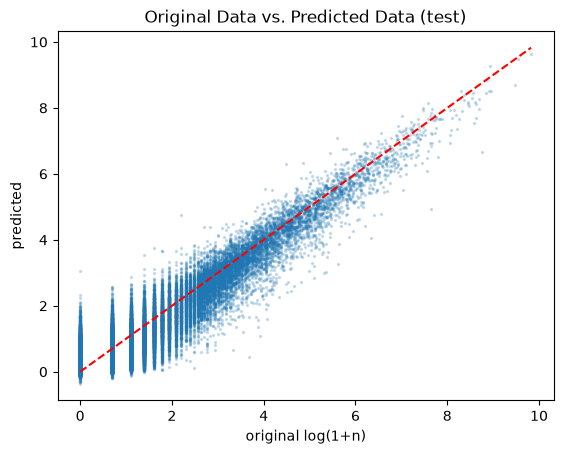

,Linear (Ridge),Neural net
Test RMSE (log),0.7742,0.4404
Test R^2,0.6609,0.8903
Test RMSE (people),169.0300,70.0262
Test MAE (people),13.7500,6.1380


In [19]:
pred = predict(res, test)
plt.scatter(test["y"], pred, s=2, alpha=0.2)
lim = [0, test["y"].max()]
plt.plot(lim, lim, "r--")
plt.xlabel("original log(1+n)"); plt.ylabel("predicted"); plt.title("Original Data vs. Predicted Data (test)")
plt.show()

cm = count_metrics(res, test)
compare = pd.DataFrame(
    {"Linear (Ridge)": [0.7742, 0.6609, 169.03, 13.75],
     "Neural net": [np.sqrt(mean_squared_error(test["y"], pred)), r2_score(test["y"], pred),
                    cm["rmse_people"], cm["mae_people"]]},
    index=["Test RMSE (log)", "Test R^2", "Test RMSE (people)", "Test MAE (people)"])
compare.round(4)

## Ablation

Ablation test to see the effect of individual features. Each input, then feature group, is removed and the network is then retrained on the same hyperparameters. Validation is compared to the full model then averaged over 3 seeds. For interpretation, a large increase means that the model is reliant on that given input.

In [20]:
Xtr, Xva, imp, _ = make_xy(final_groups)
sc = StandardScaler().fit(Xtr)
Xt_all, Xv_all = sc.transform(Xtr), sc.transform(Xva)
cols = list(Xtr.columns)
cfg = CONFIGS[0]

def score(keep, seeds=(0, 1, 2)):
    i = [cols.index(c) for c in keep]
    return np.mean([train_net(Xt_all[:, i], train["y"], Xv_all[:, i], val["y"], seed=s, **cfg)[1]
                    for s in seeds])

full = score(cols)
print("all inputs, val RMSE:", round(full, 4))

rows = [{"removed": c, "val_rmse": (r := score([x for x in cols if x != c])), "increase": r - full} for c in cols]
abl_inputs = pd.DataFrame(rows).sort_values("increase", ascending=False)
display(abl_inputs.round(4))

group_cols = {g: list(FEATURE_FUNCS[g](train.head(5)).columns) for g in final_groups}
rows = [{"removed": g, "val_rmse": (r := score([c for c in cols if c not in group_cols[g]])), "increase": r - full}
        for g in final_groups]
abl_groups = pd.DataFrame(rows).sort_values("increase", ascending=False)
display(abl_groups.round(4))

all inputs, val RMSE: 0.4417


,removed,val_rmse,increase
0,log_pop_o,0.4909,0.0492
4,same_state,0.4574,0.0157
6,log_inc_d,0.4527,0.0110
5,pov_d,0.4503,0.0086
1,log_pop_d,0.4441,0.0024
10,poor_health_pct_d,0.4433,0.0016
7,pov_gap,0.4429,0.0012
2,log_dist,0.4428,0.0011
13,obesity_pct_d,0.4428,0.0011
9,poor_health_pct_o,0.4428,0.0011


,removed,val_rmse,increase
0,pop_census,0.4950,0.0533
5,health,0.4777,0.0360
3,dest_econ,0.4757,0.0340
2,same_state,0.4574,0.0157
4,econ_gap,0.4451,0.0034
1,distance,0.4419,0.0002
6,interact,0.4411,-0.0006


Two contrasting pairs of origin-destination with different characteristics are tested here. The two pairs we choose are Casper, WY to Seattle, WA (sparse/red to dense/blue) and Boston, MA to Dallas, TX (dense/blue to dense/red). Both are long distances, but the first pair is small flow expected and the second is large flow expected.

In [21]:
test[(test["n"] >= 20) & (test["n"] <= 300)][["o_cz_name", "o_state_name", "d_cz_name", "d_state_name", "n"]]. \
    sort_values("n", ascending=False).head(40)

,o_cz_name,o_state_name,d_cz_name,d_state_name,n
122764,Jackson,Mississippi,Washington DC,DC,300.0
395648,El Paso,Texas,Lubbock,Texas,300.0
529793,Flagstaff,Arizona,San Diego,California,300.0
76456,Providence,Rhode Island,Cape Coral,Florida,300.0
409294,Texarkana,Texas,Austin,Texas,299.0
409288,Nashville,Tennessee,Austin,Texas,298.0
548222,Toms River,New Jersey,Seattle,Washington,296.0
197759,Richmond,Virginia,Newark,New Jersey,295.0
526610,El Paso,Texas,San Francisco,California,295.0
207425,Miami,Florida,Providence,Rhode Island,294.0


In [22]:
PAIRS = {
    "A: Casper WY -> Seattle WA":  ("Casper", "Wyoming", "Seattle", "Washington"),
    "B: Boston MA -> Dallas TX":   ("Boston", "Massachusetts", "Dallas", "Texas"),
}

def find_pair(o_name, o_state, d_name, d_state):
    m = data[data["o_cz_name"].str.contains(o_name, case=False, regex=False) & (data["o_state_name"] == o_state) & data["d_cz_name"].str.contains(d_name, case=False, regex=False) & (data["d_state_name"] == d_state)]
    return m

for label, spec in PAIRS.items():
    m = find_pair(*spec)
    print(label, "->", len(m), "match(es)")
    if len(m) != 1:
        display(m[["o_cz", "o_cz_name", "o_state_name", "d_cz", "d_cz_name", "d_state_name", "n"]])

A: Casper WY -> Seattle WA -> 1 match(es)
B: Boston MA -> Dallas TX -> 1 match(es)


In [23]:
test_abs_resid = (test["y"] - predict(res, test)).abs()

out = {}
for label, spec in PAIRS.items():
    m = find_pair(*spec)
    if m.empty:
        print("not found:", label); continue
    i = m.index[0]
    row = data.loc[[i]]
    split = "train" if i in train.index else "val" if i in val.index else "test"
    p = predict(res, row)[0]
    p_n = max(np.expm1(p), 0) if LOG_TARGET else max(p, 0)
    actual = row["n_clean"].iloc[0]
    resid = row["y"].iloc[0] - p
    out[label] = {
        "split (test = out-of-sample)": split,
        "actual movers": actual,
        "predicted movers": round(p_n, 1),
        "error (people)": round(p_n - actual, 1),
        "residual (target units)": round(resid, 3),
        "abs error percentile in test set": f"{(test_abs_resid < abs(resid)).mean():.0%}",
        "distance (km)": round(float(pair_km(row)[0]), 0),
        "origin pop": f"{lookup(row, 'pop', 'o')[0]:,.0f}",
        "dest pop": f"{lookup(row, 'pop', 'd')[0]:,.0f}",
        "origin poverty %": round(float(lookup(row, "poverty_pct", "o")[0]), 1),
        "dest poverty %": round(float(lookup(row, "poverty_pct", "d")[0]), 1),
        "origin median income": f"{lookup(row, 'median_income', 'o')[0]:,.0f}",
        "dest median income": f"{lookup(row, 'median_income', 'd')[0]:,.0f}",
        "same state": row["o_state_name"].iloc[0] == row["d_state_name"].iloc[0],
    }

pd.DataFrame(out)

,A: Casper WY -> Seattle WA,B: Boston MA -> Dallas TX
split (test = out-of-sample),train,train
actual movers,95.0,682.0
predicted movers,74.900002,672.799988
error (people),-20.1,-9.2
residual (target units),0.235,0.014
abs error percentile in test set,53%,4%
distance (km),1363.0,2476.0
origin pop,"89,300","5,164,258"
dest pop,"4,285,937","4,198,387"
origin poverty %,9.2,8.9


**Notes from the table above:**
Both pairs are under-predicted and both landed in the train set. Pair B is worse, having an error of -637 people vs. -81. Looking at it scaled, the model is off by about 15x on Boston -> Dallas and 6.5x on Casper -> Seattle. This indicates that the model is underfitting. 

## Results vs. Expectations 

| Expectation | What happened |
|---|---|
| The network beats linear regression, since it can learn interactions and nonlinear effects itself | Confirmed: test RMSE 0.440 vs 0.774 (log units), R² 0.890 vs 0.661, RMSE 70 vs 169 people, MAE 6.1 vs 13.7 people |
| Bigger networks do better | Partly: 256×3 was best (0.442), 64×2 was worst (0.494). 256×3 also used a lower learning rate, so width and learning rate can't be separated |
| ReLU vs Tanh | ReLU slightly better (0.445 vs 0.451, same size and learning rate) |
| Hand-built features matter less for a network | Not tested directly. Ablation shows many gap and interaction inputs add almost nothing (changes under 0.002) |

## Limitations

- Trained on CPU only so the search covers only 4 configurations and a single seed. The top two configurations differ by only 0.004.
- The best model was still improving at epoch 60 (validation RMSE 0.4454 → 0.4417 over the last 10 epochs), so early stopping never triggered. More epochs would likely help slightly. This was not changed after the test result was seen.
- The train/validation/test split is random by row, so the same commuting zones appear in all three splits. A network can identify a zone from its unique population and income values, so test accuracy reflects predicting new pairs between known zones, not unseen zones.
- The group ablation used a 100,000-row subsample, 15 epochs and one seed to keep run time down, so it is noisier than the per-input table. Differences under about 0.005 are within noise.

## Conclusions and Key Takeaways


**The neural network clearly outperforms linear regression.** On the same features and split, test RMSE fell from 0.774 to 0.440 (log units) and R² rose from 0.661 to 0.890. In people, RMSE fell from 169 to 70 and mean absolute error from 13.7 to 6.1. Test (0.440) matched validation (0.442), so the gain isn't an artifact of tuning. The earlier gradient-boosting check suggested the linear model was missing nonlinear structure, and the network captures it.

**Which inputs matter (ablation).** Removing whole groups raised validation RMSE most for Census population (+0.053), then health (+0.036), destination economy (+0.034) and same-state (+0.016). Economic gaps added little (+0.003). The distance group (+0.0002) and the distance-population interaction (−0.0006) changed nothing beyond noise. By single input, origin population was most important (+0.049), then same-state (+0.016), destination income (+0.011) and destination poverty (+0.009). The health group matters far more than any single health input (all under +0.002), so its inputs overlap with each other and with other features.

**This differs sharply from the linear model**, where distance gave the largest single improvement. A likely explanation, not tested here, is that the per-zone inputs form a nearly unique fingerprint for each commuting zone. Because the same zones appear in all three splits, the network can learn each zone's flows, including how far apart zones are, from other rows. That would also explain why population and health rank so high. So the ablation measures how much information an input carries about zone identity, not necessarily how much it drives migration. An easy test is to rerun with a split by origin zone.

**Future work:** train longer on a GPU, search more configurations over multiple seeds, split by origin zone to test generalization to unseen zones, and add learned per-zone embeddings.